This is a CNN model with binary classification of Covid vs Normal (Healthy)

2 datasets are being used.<br> 2 classes were taken from dataset1 - Covid and Normal (Healthy)
<br>1 class was taken from dataset 2 -Covid positive


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#paths for 2 datasets. Covid

pathC_d1 = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/COVID-19 Radiography Database/COVID"
pathN_d1 = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/COVID-19 Radiography Database/NORMAL"

pathC_d2 = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/COVIDGR 1.0/COVIDGR_1.0/P"

manifest1_path = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/manifests/dataset1_clean_manifest.csv"
manifest2_path = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/manifests/dataset2_clean_manifest.csv"

In [3]:
import os

datasets_root = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets"

for root, dirs, files in os.walk(datasets_root):
    if os.path.basename(root) == "P":
        print(root)

/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/COVIDGR 1.0/COVIDGR_1.0/P


In [4]:
import os

# Function to count image files
def count_images(folder):
    extensions = (".png", ".jpg", ".jpeg", ".bmp")

    return sum(
        1 for f in os.listdir(folder)
        if f.lower().endswith(extensions)
    )


print("Dataset 1 COVID :", count_images(pathC_d1))
print("Dataset 1 Normal:", count_images(pathN_d1))
print("Dataset 2 COVID :", count_images(pathC_d2))

Dataset 1 COVID : 1200
Dataset 1 Normal: 1341
Dataset 2 COVID : 426


In [5]:
import pandas as pd
import os

manifest1 = pd.read_csv(manifest1_path)   #covid radiograpghy db
manifest2 = pd.read_csv(manifest2_path)   #covidgr 1.0

In [6]:
# -------------------------
# Dataset 1 - COVID
# -------------------------
d1_covid = manifest1[
    manifest1["label"] == "COVID"
].copy()

d1_covid["filepath"] = d1_covid["filename"].apply(
    lambda x: os.path.join(pathC_d1, x)
)

d1_covid["class"] = "COVID"
d1_covid["source"] = "Dataset1"


# -------------------------
# Dataset 1 - Normal
# -------------------------
d1_normal = manifest1[
    manifest1["label"] == "Healthy"
].copy()

d1_normal["filepath"] = d1_normal["filename"].apply(
    lambda x: os.path.join(pathN_d1, x)
)

d1_normal["class"] = "Normal"
d1_normal["source"] = "Dataset1"


# -------------------------
# Dataset 2 - COVID
# -------------------------
d2_covid = manifest2[
    manifest2["original_label"] == "COVID"
].copy()

d2_covid["filepath"] = d2_covid["filename"].apply(
    lambda x: os.path.join(pathC_d2, x)
)

d2_covid["class"] = "COVID"
d2_covid["source"] = "Dataset2"

In [7]:
modelB_df = pd.concat(
    [
        d1_covid[["filename", "filepath", "class", "source"]],
        d1_normal[["filename", "filepath", "class", "source"]],
        d2_covid[["filename", "filepath", "class", "source"]]
    ],
    ignore_index=True
)

print("Total images:", len(modelB_df))

print("\nClass counts:")
print(modelB_df["class"].value_counts())

print("\nSource + class counts:")
print(modelB_df.groupby(["source", "class"]).size())

display(modelB_df.head())

Total images: 2966

Class counts:
class
COVID     1626
Normal    1340
Name: count, dtype: int64

Source + class counts:
source    class 
Dataset1  COVID     1200
          Normal    1340
Dataset2  COVID      426
dtype: int64


,filename,filepath,class,source
0,COVID (365).png,/content/drive/MyDrive/PSUPRProject_2026Sem2/d...,COVID,Dataset1
1,COVID (529).png,/content/drive/MyDrive/PSUPRProject_2026Sem2/d...,COVID,Dataset1
2,COVID (412).png,/content/drive/MyDrive/PSUPRProject_2026Sem2/d...,COVID,Dataset1
3,COVID (707).png,/content/drive/MyDrive/PSUPRProject_2026Sem2/d...,COVID,Dataset1
4,COVID (650).png,/content/drive/MyDrive/PSUPRProject_2026Sem2/d...,COVID,Dataset1


In [8]:
modelB_df["exists"] = modelB_df["filepath"].apply(os.path.exists)

print("Files found :", modelB_df["exists"].sum())
print("Files missing:", (~modelB_df["exists"]).sum())

if not modelB_df["exists"].all():
    display(modelB_df[~modelB_df["exists"]])

Files found : 2966
Files missing: 0


In [9]:
modelB_df = modelB_df.drop(columns=["exists"], errors="ignore")

check for duplicates

In [10]:
!pip install -q imagehash

#hash every image
import io
import hashlib
import numpy as np
import imagehash
from PIL import Image
from tqdm.auto import tqdm

md5s, phashes = [], []

for fp in tqdm(modelB_df["filepath"], desc="Hashing images"):
    with open(fp, "rb") as f:
        data = f.read()
    md5s.append(hashlib.md5(data).hexdigest())                   # exact duplicate check
    img = Image.open(io.BytesIO(data)).convert("L")              # grayscale
    phashes.append(imagehash.phash(img))                         # 64-bit perceptual hash

modelB_df["md5"] = md5s
print("Exact duplicates (byte-identical files):", modelB_df["md5"].duplicated().sum())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 7.8 MB/s eta 0:00:00


Hashing images:   0%|          | 0/2966 [00:00<?, ?it/s]

Exact duplicates (byte-identical files): 0


In [14]:
#comparre all pairs and group near dups
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

# Hamming distance between every pair of pHashes, computed as a matrix product (fast)
bits = np.array([h.hash.flatten() for h in phashes]).astype(np.int32)   # (N, 64)
ones = bits.sum(axis=1)
hamming = ones[:, None] + ones[None, :] - 2 * (bits @ bits.T)          # (N, N)

# How many image pairs fall at each distance level (upper triangle, excluding self-pairs)
iu = np.triu_indices(len(bits), k=1)
pair_d = hamming[iu]
for t in [0, 2, 4, 6, 8, 10]:
    print(f"Pairs with Hamming distance <= {t:2d}: {(pair_d <= t).sum()}")

# Group images connected by distance <= THRESH (duplicates of duplicates end up in one group)
THRESH = 2
n_groups, group_id = connected_components(csr_matrix(hamming <= THRESH), directed=False)
modelB_df["dup_group"] = group_id

sizes = modelB_df.groupby("dup_group").size()
dup_ids = sizes[sizes > 1].index
dups = modelB_df[modelB_df["dup_group"].isin(dup_ids)]

print(f"\nThreshold = {THRESH}")
print("Duplicate groups:", len(dup_ids))
print("Images inside duplicate groups:", len(dups))
print("Images that would be removed:", len(dups) - len(dup_ids))

# Groups whose members have DIFFERENT labels (the same X-ray labelled both COVID and Normal)
n_cls = dups.groupby("dup_group")["class"].nunique()
print("Groups with conflicting labels:", (n_cls > 1).sum())

# Groups spanning both datasets (same X-ray in Dataset1 AND Dataset2)
n_src = dups.groupby("dup_group")["source"].nunique()
print("Groups spanning both datasets:", (n_src > 1).sum())

print("\nDuplicate images by source/class:")
print(dups.groupby(["source", "class"]).size())

# Largest groups (chaining check): real duplicate groups should be small (2-3 images)
print("\nLargest group sizes:", sizes.sort_values(ascending=False).head(10).tolist())

# Details of conflicting-label groups
conflict_ids = n_cls[n_cls > 1].index
print("\nConflicting-label groups:")
display(modelB_df[modelB_df["dup_group"].isin(conflict_ids)][["dup_group", "source", "class", "filename"]])

Pairs with Hamming distance <=  0: 199
Pairs with Hamming distance <=  2: 281
Pairs with Hamming distance <=  4: 474
Pairs with Hamming distance <=  6: 1489
Pairs with Hamming distance <=  8: 6113
Pairs with Hamming distance <= 10: 20895

Threshold = 2
Duplicate groups: 175
Images inside duplicate groups: 403
Images that would be removed: 228
Groups with conflicting labels: 0
Groups spanning both datasets: 0

Duplicate images by source/class:
source    class 
Dataset1  COVID     376
          Normal     27
dtype: int64

Largest group sizes: [6, 4, 4, 4, 4, 4, 4, 4, 3, 3]

Conflicting-label groups:


,dup_group,source,class,filename


Pairs at exactly d=2: 82 (showing 6)


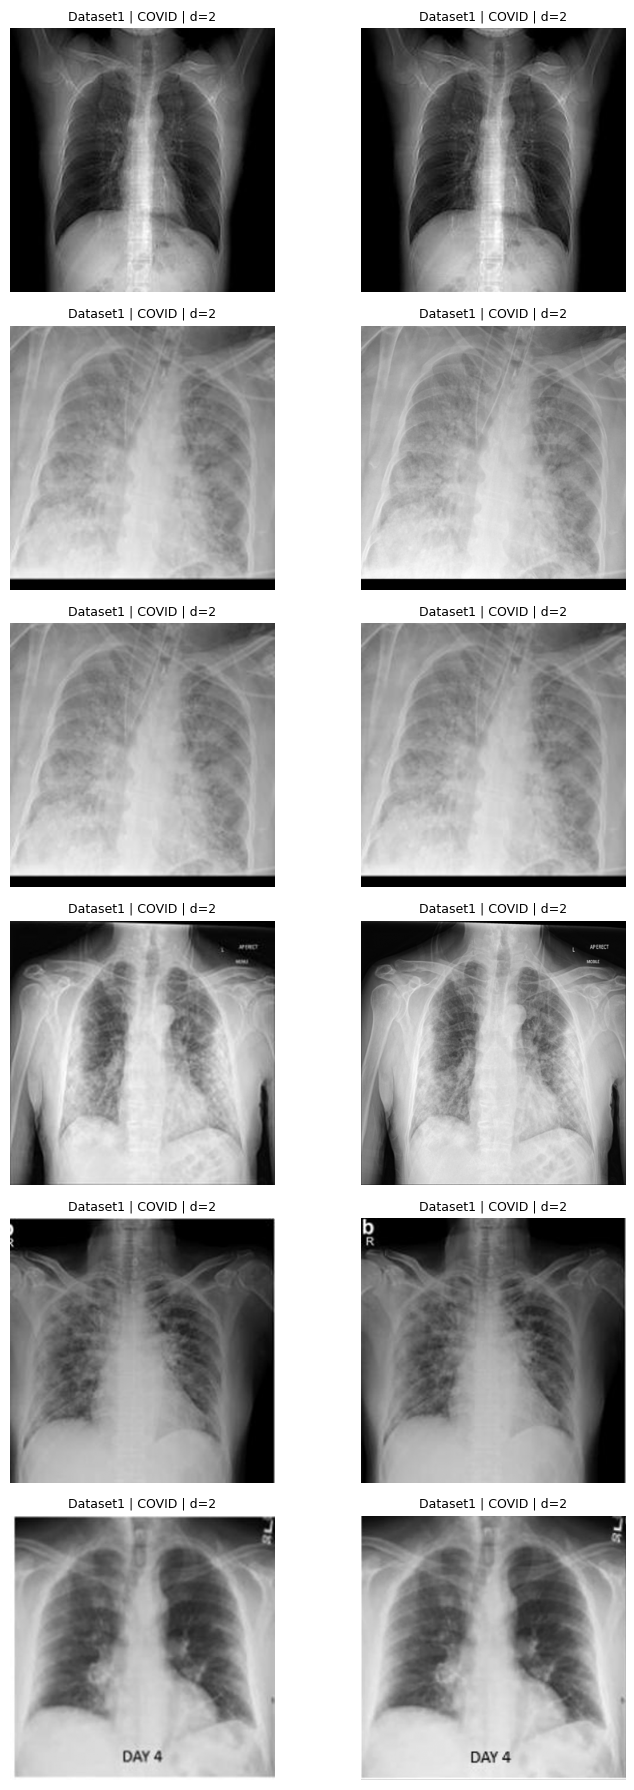

In [15]:
#look at duplicate cells

import matplotlib.pyplot as plt

# Pairs exactly at the threshold (the borderline cases)
ii, jj = np.where(np.triu(hamming == THRESH, k=1))
n_show = min(6, len(ii))
print(f"Pairs at exactly d={THRESH}: {len(ii)} (showing {n_show})")

plt.figure(figsize=(8, 3 * n_show))
for row in range(n_show):
    for col, k in enumerate([ii[row], jj[row]]):
        r = modelB_df.iloc[k]
        plt.subplot(n_show, 2, row * 2 + col + 1)
        plt.imshow(Image.open(r["filepath"]).convert("L"), cmap="gray")
        plt.title(f"{r['source']} | {r['class']} | d={THRESH}", fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

Largest group: id=238, size=6
source    class
Dataset1  COVID    6
dtype: int64


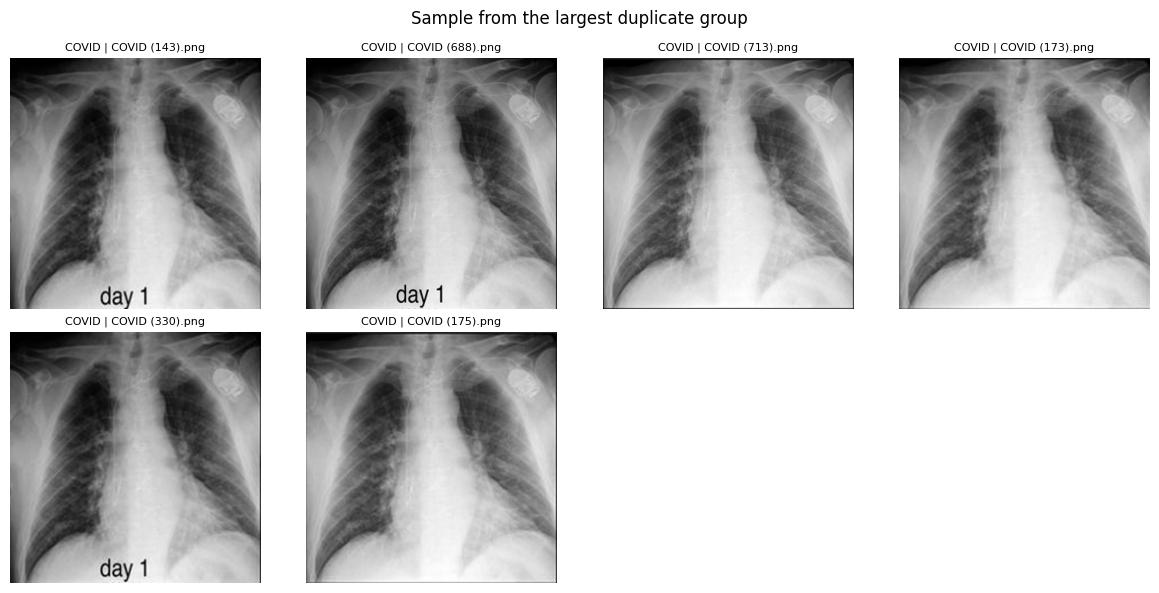

In [17]:
# Inspect the largest duplicate group: true copies, or chained look-alikes?
largest_id = sizes.idxmax()
members = modelB_df[modelB_df["dup_group"] == largest_id]
print(f"Largest group: id={largest_id}, size={len(members)}")
print(members.groupby(["source", "class"]).size())

sample = members.sample(min(8, len(members)), random_state=42)
plt.figure(figsize=(12, 6))
for i, (_, r) in enumerate(sample.iterrows()):
    plt.subplot(2, 4, i + 1)
    plt.imshow(Image.open(r["filepath"]).convert("L"), cmap="gray")
    plt.title(f"{r['class']} | {r['filename'][:15]}", fontsize=8)
    plt.axis("off")
plt.suptitle("Sample from the largest duplicate group")
plt.tight_layout()
plt.show()

REMOVE DUPLICATES


In [18]:
# Keep ONE image per duplicate group (the first one), drop the rest
before = len(modelB_df)
print("BEFORE dedup:")
print(modelB_df.groupby(["source", "class"]).size(), "\n")

modelB_df = (
    modelB_df
    .drop_duplicates(subset="dup_group", keep="first")
    .drop(columns=["md5", "dup_group"])
    .reset_index(drop=True)
)

print("AFTER dedup:")
print(modelB_df.groupby(["source", "class"]).size())
print(f"\nRemoved {before - len(modelB_df)} near-duplicate images. Remaining: {len(modelB_df)}")
print("\nClass balance:")
print(modelB_df["class"].value_counts(normalize=True).round(3))

# Save the cleaned list so future runs can skip the slow hashing step
dedup_path = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/manifests/modelB_dedup_manifest.csv"
modelB_df.to_csv(dedup_path, index=False)
print("\nSaved:", dedup_path)

BEFORE dedup:
source    class 
Dataset1  COVID     1200
          Normal    1340
Dataset2  COVID      426
dtype: int64 

AFTER dedup:
source    class 
Dataset1  COVID      987
          Normal    1325
Dataset2  COVID      426
dtype: int64

Removed 228 near-duplicate images. Remaining: 2738

Class balance:
class
COVID     0.516
Normal    0.484
Name: proportion, dtype: float64

Saved: /content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/manifests/modelB_dedup_manifest.csv


TRAIN TEST SPLIT


In [19]:
from sklearn.model_selection import train_test_split

#70% train 30% temp
#this 30% will become 15% 15% for validation and testing
train_df, temp_df = train_test_split(
    modelB_df,
    test_size = 0.30,
    random_state=42,
    stratify=modelB_df["class"]
)


#30% temp
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=32,
    stratify=temp_df["class"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Train: 1916
Validation: 411
Test: 411


In [20]:
#check if the class distribution stays approximately the same

print("\nTRAIN")
print(train_df["class"].value_counts())
print(train_df["class"].value_counts(normalize=True).round(3))

print("\nVALIDATION")
print(val_df["class"].value_counts())
print(val_df["class"].value_counts(normalize=True).round(3))

print("\nTEST")
print(test_df["class"].value_counts())
print(test_df["class"].value_counts(normalize=True).round(3))


TRAIN
class
COVID     989
Normal    927
Name: count, dtype: int64
class
COVID     0.516
Normal    0.484
Name: proportion, dtype: float64

VALIDATION
class
COVID     212
Normal    199
Name: count, dtype: int64
class
COVID     0.516
Normal    0.484
Name: proportion, dtype: float64

TEST
class
COVID     212
Normal    199
Name: count, dtype: int64
class
COVID     0.516
Normal    0.484
Name: proportion, dtype: float64


224 X 224 Pixel Normalization

In [21]:
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED) # (covers weight initialization and dropout)
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

In [22]:
#Function to read an image from its filepath, decodes it, resizes it and normalizes it

def load_and_preprocess_image(filepath,label):

  #read image
  image = tf.io.read_file(filepath)

  #decode image and force 3 channels
  image = tf.io.decode_image(
      image,
      channels=3,
      expand_animations=False #this will force 3D tensor (height, width, channels)
  )

  #resize to 224 x 224, use pad with black instead of stretching
  image = tf.image.resize_with_pad(image, IMG_SIZE[0], IMG_SIZE[1])


  #convert pixel values from -0255 to 0-1
  image = tf.cast(image, tf.float32) / 255.0

  return image, label

DATA AUGMENTATION

In [23]:
from tensorflow import keras
from tensorflow.keras import layers

#mild xray safe augmentation. no horizonatal flips
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.02, fill_mode="constant", seed=SEED), #ABOUT +-7 DEGREES
    layers.RandomTranslation(0.05, 0.05, fill_mode="constant", seed=SEED), # shift up to 5%
    layers.RandomZoom(0.1, fill_mode="constant", seed=SEED), # zoom ±10%
    layers.RandomBrightness(0.1, value_range=(0,1), seed=SEED),  # brightness ±10%, clipped to [0,1]
], name="data_augmentation")

def augment(images,labels):
  return data_augmentation(images, training=True), labels

  #fill_mode = constant fills the empty edges from rotation or shifting with black which matches the padding that is gonna be added later - value_range = (0,1)

In [24]:
#label mapping

label_map = {
    "Normal" : 0,
    "COVID" : 1
}

train_df["label_num"] = train_df["class"].map(label_map)
val_df["label_num"]   = val_df["class"].map(label_map)
test_df["label_num"]  = test_df["class"].map(label_map)

print(train_df[["filename", "class", "label_num"]].head())

              filename   class  label_num
228   COVID (1008).png   COVID          1
444   COVID (1134).png   COVID          1
104    COVID (218).png   COVID          1
984   COVID (1065).png   COVID          1
1117  NORMAL (246).png  Normal          0


In [25]:
#CONVERT the dataframes into tensorflow datasets

def create_dataset(df, training=False):

  dataset = tf.data.Dataset.from_tensor_slices(
      (
          df["filepath"].values,
          df["label_num"].values
      )
  )

#load and preprocess images (deterministic: read, decode, resize_with_pad, normalize)
  dataset = dataset.map(
      load_and_preprocess_image,
      num_parallel_calls=tf.data.AUTOTUNE
  )

#cache preprocessed images in RAM (1st epoch reads from Drive, later epochs read from memory)
  dataset = dataset.cache()

#shuffle training data only (AFTER cache, so order changes every epoch)
  if training:
    dataset = dataset.shuffle(
        buffer_size=len(df),
        seed=SEED
    )

#group images into batches
  dataset = dataset.batch(BATCH_SIZE)

#augment training data only (AFTER cache, so augmentations stay random every epoch)
  if training:
    dataset = dataset.map(
        augment,
        num_parallel_calls=tf.data.AUTOTUNE
    )

#Prepare next batch while gpu is working
  dataset = dataset.prefetch(tf.data.AUTOTUNE)

  return dataset

In [26]:
checkpoint_path = "/content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_v2_27sep.keras"

In [27]:
train_ds = create_dataset(train_df, training=True)
val_ds   = create_dataset(val_df)
test_ds  = create_dataset(test_df)

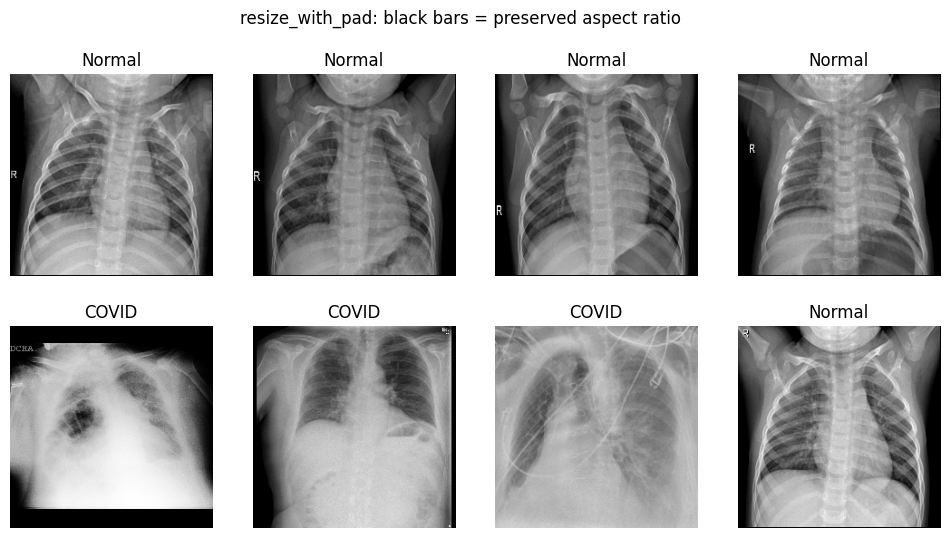

Dataset1 | Normal | 1024x1024  (ratio 1.00)
Dataset1 | COVID  | 256x256  (ratio 1.00)
Dataset1 | Normal | 1024x1024  (ratio 1.00)
Dataset2 | COVID  | 2332x2688  (ratio 0.87)
Dataset2 | COVID  | 2728x2578  (ratio 1.06)
Dataset2 | COVID  | 2740x2844  (ratio 0.96)


In [28]:
import matplotlib.pyplot as plt

# One unaugmented batch from val_ds, show a mix of sources/classes
for images, labels in val_ds.take(1):
    plt.figure(figsize=(12, 6))
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy())
        plt.title("COVID" if labels[i].numpy() == 1 else "Normal")
        plt.axis("off")
    plt.suptitle("resize_with_pad: black bars = preserved aspect ratio")
    plt.show()

# Show original sizes of a few files from each source, to see how much they differ
import PIL.Image as Image
for src in ["Dataset1", "Dataset2"]:
    sample = modelB_df[modelB_df["source"] == src].sample(3, random_state=SEED)
    for _, row in sample.iterrows():
        w, h = Image.open(row["filepath"]).size
        print(f"{src} | {row['class']:6} | {w}x{h}  (ratio {w/h:.2f})")

In [29]:
#verify what CNN will actually receive
for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("\nPixel minimum:", tf.reduce_min(images).numpy())
    print("Pixel maximum:", tf.reduce_max(images).numpy())

    print("\nFirst 10 labels:")
    print(labels[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)

Pixel minimum: 0.0
Pixel maximum: 1.0

First 10 labels:
[1 0 1 0 0 1 0 1 1 1]


START TRAINING CNN FOR NORMAL = 0 , COVID = 1. BINARY CLASSIFICATION

In [30]:
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(SEED) # re-seed so re-running this cell alone gives identical initial weights
model_B = keras.Sequential([
    #input
    layers.Input(shape=(224, 224, 3)),

    #concolution block 1
    layers.Conv2D(
        filters=32,
        kernel_size=(3,3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2,2)),

    #concolution block 2
    layers.Conv2D(
        filters=64,
        kernel_size=(3,3),
        activation="relu",
        padding="same"
    ),
       layers.MaxPooling2D(pool_size=(2,2)),

    #convolution block3
    layers.Conv2D(
        filters=128,
        kernel_size=(3,3),
        activation="relu",
        padding="same"
    ),
       layers.MaxPooling2D(pool_size=(2,2)),

    #convert featur maps to a vector
    layers.Flatten(),

    #classification
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    #binary output
    layers.Dense(1, activation="sigmoid")
])

model_B.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,561 (49.36 MB)

 Trainable params: 12,938,561 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
print(model_B.layers[0].get_weights()[0].sum())

-3.0186365


896 parameters come from
(3 x 3 x 3 + 1 ) x 32 = 896

In [31]:
#compile
model_B.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

Adam → optimizer that updates the ~12.9 million trainable parameters.
learning_rate=0.001 → standard starting point for Adam.
binary_crossentropy → appropriate because we have binary classification: Normal=0, COVID=1.
accuracy → tracks classification accuracy while training.

In [32]:
#checkpoint saving and callback since colab can get stuck
#checkpoint_path = "/content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_25sep.keras"
checkpoint_path = "/content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_v2_27sep.keras"

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

In [33]:
csv_logger_cb = keras.callbacks.CSVLogger(
    "/content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_v2_history_27sep.csv"
)

In [34]:
earlystop_cb = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,                     #early stopping if the validation loss doesnt beat the best value for 5 consecutive epochs
    mode="min",
    restore_best_weights=True,
    verbose=1
)

In [35]:
history_B = model_B.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[
        checkpoint_cb,
        earlystop_cb,
        csv_logger_cb
    ]
)

Epoch 1/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step - accuracy: 0.7904 - loss: 0.4076
Epoch 1: val_loss improved from None to 0.10358, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_v2_27sep.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_v2_27sep.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 44s 600ms/step - accuracy: 0.8967 - loss: 0.2382 - val_accuracy: 0.9635 - val_loss: 0.1036
Epoch 2/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step - accuracy: 0.9697 - loss: 0.0857
Epoch 2: val_loss improved from 0.10358 to 0.06301, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_v2_27sep.keras

Epoch 2: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_v2_27sep.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 385ms/step - accuracy: 0.9734 - loss: 0.0821 - val_accuracy: 0.9805 - val_loss: 0.0630
Epoch 3/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.9680 - loss: 0.0941
Epo

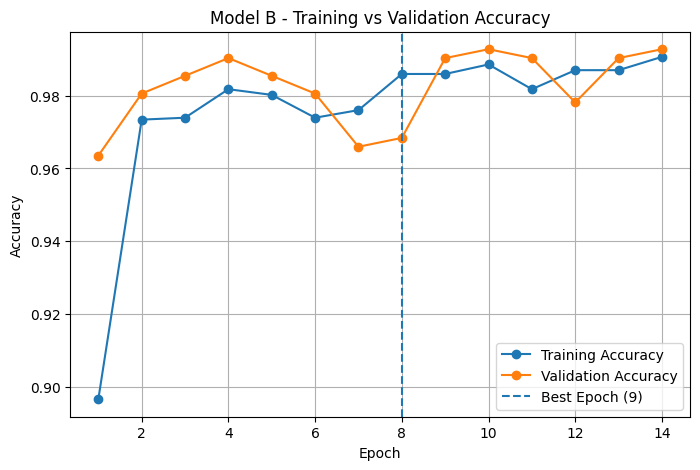

In [40]:
import matplotlib.pyplot as plt

# Extract training history
train_acc = history_B.history["accuracy"]
val_acc   = history_B.history["val_accuracy"]

train_loss = history_B.history["loss"]
val_loss   = history_B.history["val_loss"]

epochs = range(1, len(train_acc) + 1)
import numpy as np
best_epoch = int(np.argmin(val_loss)) + 1   # epoch with the lowest validation loss (the one restored)

# Accuracy plot
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_acc, marker="o", label="Training Accuracy")
plt.plot(epochs, val_acc, marker="o", label="Validation Accuracy")

plt.axvline(
    x=8,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model B - Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

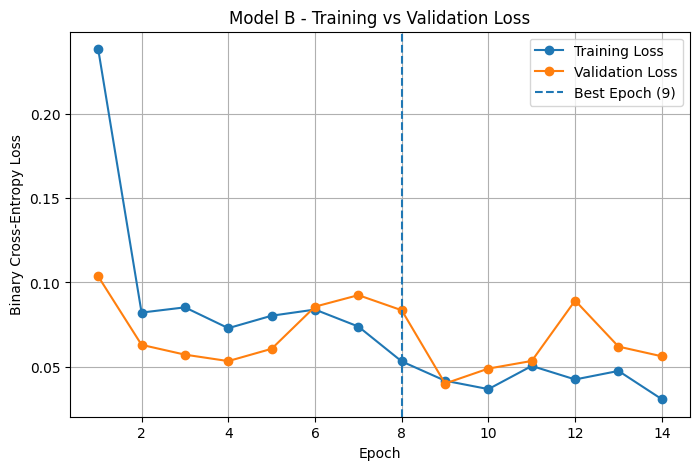

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_loss, marker="o", label="Training Loss")
plt.plot(epochs, val_loss, marker="o", label="Validation Loss")
best_epoch = int(np.argmin(val_loss)) + 1   # epoch with the lowest validation loss (the one restored)

plt.axvline(
    x=8,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Model B - Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

accuracy only asks right or wrong while binary cross-entropy also penalizes how confidently wrong the model is.

Suppose the actual Xray is covid. y = 1

case 1 -  correct and confident
<br>model predicts p = 0.99
<br>since 0.99 > 0.5, prediction = covid. so accuracy says correct.
<br><br>For a COVID sample (y=1), BCE simplifies to:
Loss=−log(p)
Therefore:

$$ -\log(0.99)=0.010 $$

Very small loss → good.

<br>Case 2 — Wrong, but not very confident
<br>Model predicts: p=0.49
<br>Since 0.49 < 0.5, prediction = Normal.
<br>Accuracy says:Wrong
<br>Loss:
−log(0.49)=0.713

<br>Case 3 — Wrong AND extremely confident
<br>Now suppose the model predicts:
$$ p=0.01 $$
It's basically saying:
"I'm 99% sure this is Normal."
But the patient is actually COVID.
<br>Accuracy still just says:Wrong
But BCE says:
−log(0.01)=4.605
That's a huge loss.

Accuracy only sees:
0.49 → WRONG
0.01 → WRONG

BCE sees:
0.49 → wrong, but close to decision boundary → loss 0.713
0.01 → extremely confident and wrong       → loss 4.605

**Training behaviour (Model B v2: seeded, augmented, resize_with_pad, deduplicated data)**

Training ran for 14 epochs. Early stopping (patience = 5) restored the weights from **epoch 9**, which had the lowest validation loss (≈ 0.040).

**Accuracy.** Training accuracy rose from ≈ 0.90 to ≈ 0.99; validation accuracy stayed between ≈ 0.96 and ≈ 0.99, peaking at ≈ 0.993. Validation accuracy is often *higher* than training accuracy, especially in early epochs. This is expected: training metrics are computed on augmented images with dropout active, while validation images are clean and dropout is off.

**Loss.** Training loss fell from ≈ 0.24 to ≈ 0.03. Validation loss dropped to its minimum at epoch 9, with spikes at epochs 7 and 12 (≈ 0.09). Because the validation set has only a few hundred images, a handful of confidently wrong predictions can move the loss noticeably, so these spikes are more likely noise than a trend.

**Comparison with v1.** In v1, training accuracy reached 100% and training loss collapsed to ≈ 0.001 while validation loss rose, a sign of memorisation. In v2, training and validation loss track each other closely, and training accuracy stays below 100%, so augmentation reduced overfitting. v2's best validation loss (≈ 0.040) is higher than v1's (≈ 0.026), but the two runs are not on identical data: v2 removed 228 near-duplicate images, many of which previously let validation/test images have a near-copy in training. The v2 figure is therefore the more honest estimate.

**Caveat.** High validation accuracy does not rule out shortcut learning. Dataset confounding (pediatric Normals, annotated publication COVID images, source-specific resolution) remains, and is examined next with Grad-CAM.

In [42]:
#use the test set
test_loss, test_accuracy = model_B.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9854 - loss: 0.0432
Test Loss: 0.043201688677072525
Test Accuracy: 0.985401451587677


the numerical values look good after testing on the test set

PREDICTIONS, CONFUSION MATRIX, PRECISION, RECALL, F1, ROC-AUC

In [43]:
#each value is the model's predicted probability of covid
y_prob = model_B.predict(test_ds)

print(y_prob[:10])
print("Shape:", y_prob.shape)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step
[[5.2262310e-02]
 [9.9208742e-01]
 [1.4235019e-07]
 [4.5294743e-03]
 [9.9999976e-01]
 [9.9820077e-01]
 [9.9994338e-01]
 [9.9879110e-01]
 [8.1649059e-06]
 [7.9406955e-06]]
Shape: (411, 1)


(445,1) meaning
445 = number of test images
1 = one sigmoid probability per image

this is the model's first 10 prob predictions
8.2416125×10−7=0.000000824
meaning the value is so close to 0. the model is very confident about Normal

In [44]:
#convert probabilities into predictions
y_pred = (y_prob.flatten() >= 0.5).astype(int)

# Actual labels
y_true = test_df["label_num"].values.astype(int)

print("Actual:   ", y_true[:20])
print("Predicted:", y_pred[:20])

Actual:    [0 1 0 0 1 1 1 1 0 0 1 0 0 0 1 0 1 1 1 0]
Predicted: [0 1 0 0 1 1 1 1 0 0 1 0 0 0 1 0 1 1 1 0]


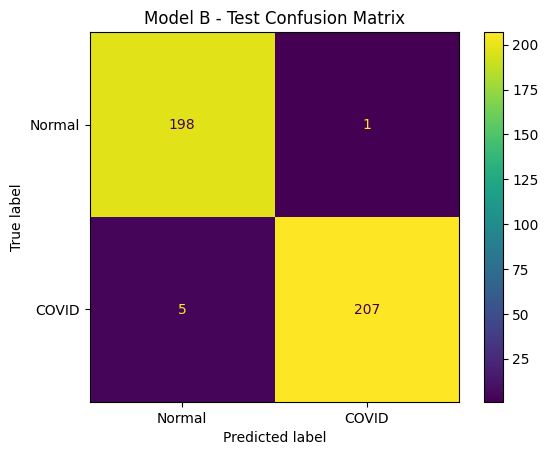

[[198   1]
 [  5 207]]


In [45]:
#confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "COVID"]
)

disp.plot()
plt.title("Model B - Test Confusion Matrix")
plt.show()

print(cm)

In [46]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Normal", "COVID"],
        digits=4
    )
)

auc = roc_auc_score(y_true, y_prob.flatten())

print("ROC-AUC:", round(auc, 4))

              precision    recall  f1-score   support

      Normal     0.9754    0.9950    0.9851       199
       COVID     0.9952    0.9764    0.9857       212

    accuracy                         0.9854       411
   macro avg     0.9853    0.9857    0.9854       411
weighted avg     0.9856    0.9854    0.9854       411

ROC-AUC: 0.9995


F1 = combines precision and recall
F1 = 2(precision x recall/precision + recall)

**Test set results (Model B v2, 411 deduplicated test images: 199 Normal, 212 COVID)**

| | Predicted Normal | Predicted COVID |
|---|---|---|
| **True Normal** | 198 (TN) | 1 (FP) |
| **True COVID** | 5 (FN) | 207 (TP) |

- **Accuracy:** 98.54% (6 errors out of 411).
- **COVID recall (sensitivity):** 97.64%: 5 COVID X-rays were missed.
- **COVID precision:** 99.52%: only 1 Normal X-ray was wrongly flagged as COVID.
- **Normal recall (specificity):** 99.50%.
- **ROC-AUC:** 0.9995.

**Comparison with v1** (99.33% accuracy: 3 FP, 0 FN). v2's errors shifted from false positives to **false negatives**. For a screening tool, missed COVID cases are the more costly error, so this matters. However, the two test sets differ (v2 removed near-duplicates), so v1's perfect COVID recall was partly helped by test images that had near-copies in training.

**Accuracy vs AUC.** AUC stayed at 0.9995 while accuracy dropped. The confidence histogram shows two kinds of missed COVID cases: 2 scored near the threshold (P ≈ 0.37 and 0.45), which a slightly lower threshold chosen on the validation set could recover, and 3 were confidently predicted Normal (P ≈ 0.12, 0.02, 0.02). Those cannot be fixed by moving the threshold; the model genuinely sees them as Normal.

All 5 errors come from Dataset1 COVID images, while Dataset2 (COVIDGR), a dataset known for difficult mild cases, scored 100%. Since every Dataset2 training image was COVID, this is consistent with the model recognising the image source rather than disease, which Grad-CAM examines next.

**Caveat.** These scores are still measured on the same mixed sources the model trained on, so they can be inflated by dataset shortcuts. Grad-CAM and cross-dataset testing address this.

ROC = Receiver Operating Characteristic curve. Instead of evaluating your model only at the 0.5 threshold, ROC asks:
What happens to COVID detection if I move the classification threshold from almost 0 all the way to 1?

True Positive Rate (Recall)=TP/(TP+FN)

False Positive Rate = FP/(FP+TN)

Threshold = 0.9  → harder to call something COVID
Threshold = 0.5  → our current classification
Threshold = 0.2  → easier to call something COVID
Usually there's a trade-off: lowering the threshold catches more COVID cases but may incorrectly flag more Normal cases.
<br>AUC = Area Under the ROC Curve.
It summarizes the entire ROC curve into one number:
<br>AUC = 0.50 → no discrimination / random-like ranking
<br>AUC = 0.80 → substantial separation
<br>AUC = 1.00 → perfect separation

My AUC = 0.9995
If I randomly select one COVID X-ray and one Normal X-ray from this test set, there is about a 99.95% chance that the model assigns the COVID image a higher COVID score than the Normal image.

So accuracy tells us performance at our chosen 0.5 threshold; ROC-AUC tells us how well the prediction scores separate the two classes across thresholds.

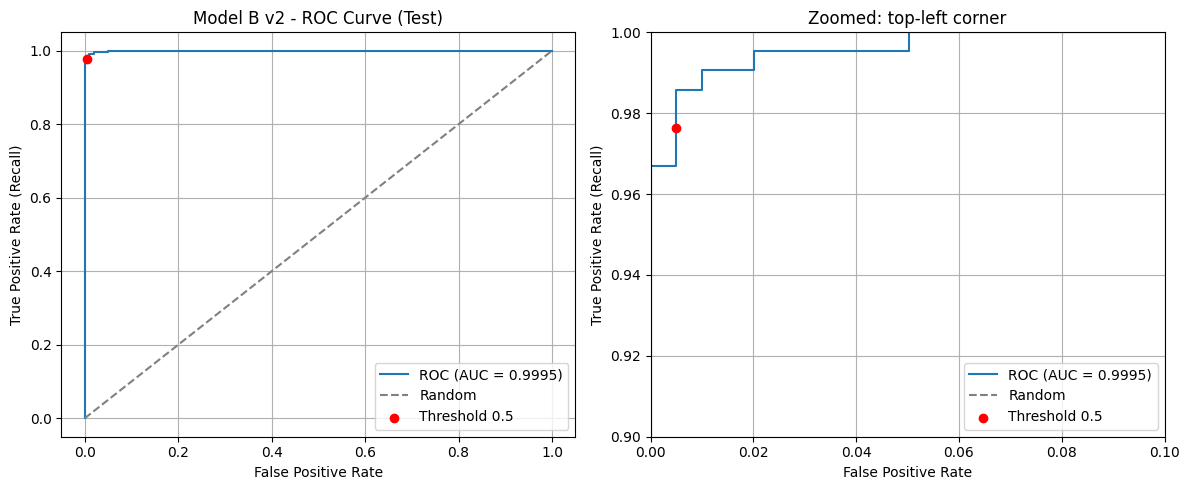

In [47]:
from sklearn.metrics import roc_curve
import numpy as np
import matplotlib.pyplot as plt

probs = y_prob.flatten()
fpr, tpr, thr = roc_curve(y_true, probs)

# Point on the curve for the 0.5 threshold currently used
tn, fp, fn, tp = cm.ravel()
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, zoom in zip(axes, [False, True]):
    ax.plot(fpr, tpr, label=f"ROC (AUC = {auc:.4f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random")
    ax.scatter(op_fpr, op_tpr, color="red", zorder=5, label="Threshold 0.5")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate (Recall)")
    ax.grid(True)
    ax.legend(loc="lower right")
    if zoom:
        ax.set_xlim(0, 0.1); ax.set_ylim(0.9, 1.0)
        ax.set_title("Zoomed: top-left corner")
    else:
        ax.set_title("Model B v2 - ROC Curve (Test)")
plt.tight_layout()
plt.show()

**ROC curve (test set).** The curve rises almost vertically at FPR = 0 and reaches the top-left corner, consistent with AUC = 0.9995. The red dot marks the current 0.5 threshold: FPR ≈ 0.005 (1 of 199 Normals flagged) and recall ≈ 0.976 (207 of 212 COVID detected).

The zoomed panel shows the recall/false-positive trade-off available by moving the threshold:

| Recall (COVID caught / 212) | False positives (of 199 Normals) |
|---|---|
| 0.976 (207): current 0.5 threshold | 1 |
| ≈ 0.986 (209) | 1 |
| ≈ 0.991 (210) | 2 |
| ≈ 0.995 (211) | 4 |
| 1.000 (212) | ≈ 10 |

The red dot sits on a vertical segment of the curve, so a slightly lower threshold would catch ~2 more COVID cases **at no extra false-positive cost**. Catching every COVID case would cost about 10 false alarms.

Any new threshold must be chosen on the **validation set**, not read off this test curve. Picking it from the test set would make the test result optimistic.

                 accuracy    n
source   class                
Dataset1 COVID     0.9645  141
         Normal    0.9950  199
Dataset2 COVID     1.0000   71


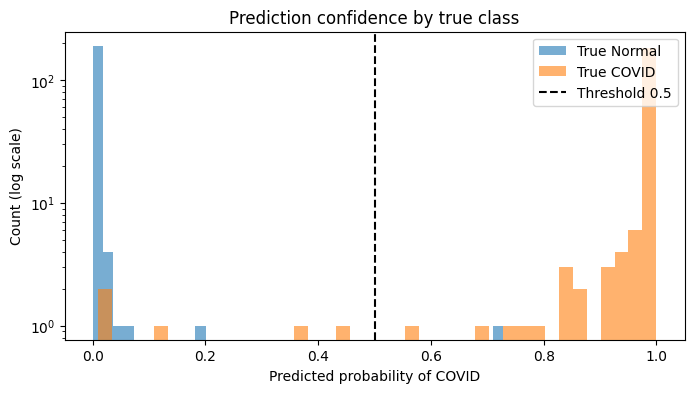

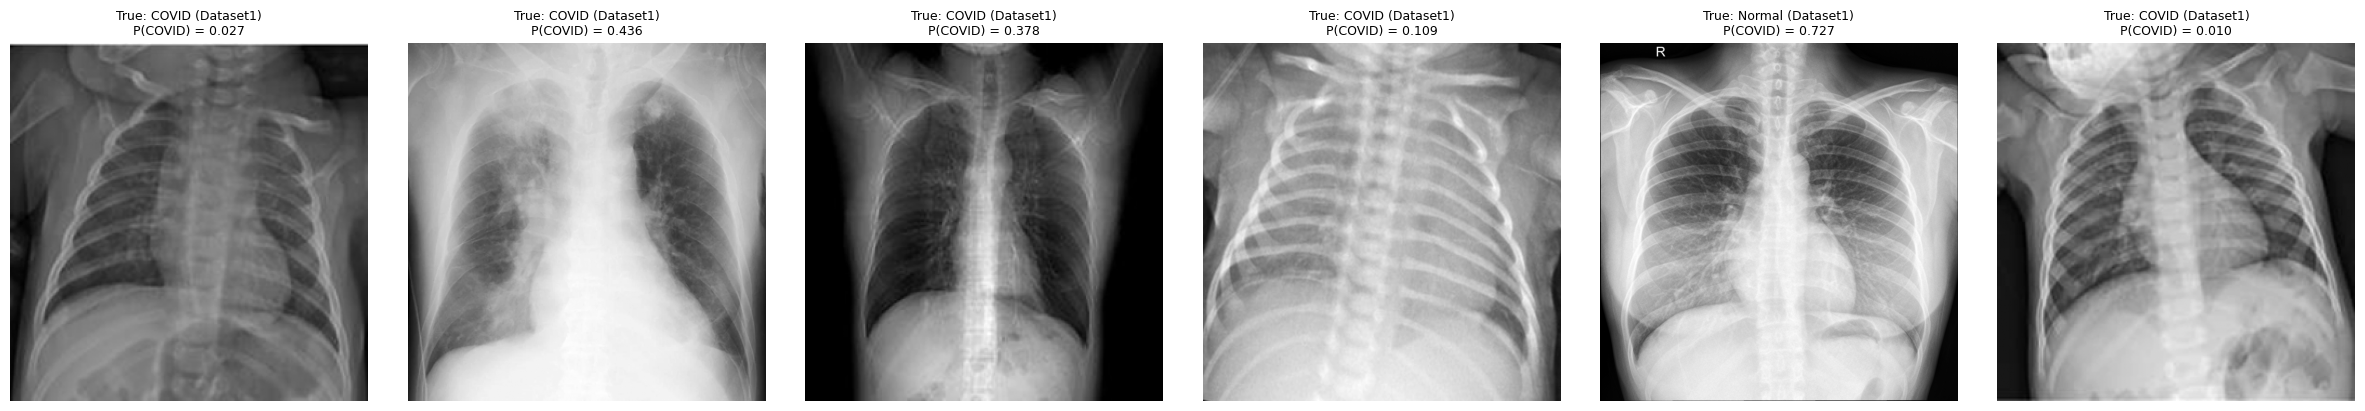

In [48]:
res = test_df.copy()
res["prob_covid"] = probs
res["pred"] = y_pred
res["correct"] = res["pred"] == res["label_num"]

# Accuracy per source/class: does performance differ between Dataset1 and Dataset2?
print(res.groupby(["source", "class"])["correct"].agg(accuracy="mean", n="count").round(4))

# Probability distribution per class: how confident/separated are predictions?
plt.figure(figsize=(8, 4))
plt.hist(res[res["class"] == "Normal"]["prob_covid"], bins=40, alpha=0.6, label="True Normal")
plt.hist(res[res["class"] == "COVID"]["prob_covid"], bins=40, alpha=0.6, label="True COVID")
plt.axvline(0.5, linestyle="--", color="black", label="Threshold 0.5")
plt.yscale("log")
plt.xlabel("Predicted probability of COVID"); plt.ylabel("Count (log scale)")
plt.title("Prediction confidence by true class")
plt.legend(); plt.show()

# Gallery of misclassified images
wrong = res[~res["correct"]]
plt.figure(figsize=(4 * len(wrong), 4))
for i, (_, r) in enumerate(wrong.iterrows()):
    plt.subplot(1, len(wrong), i + 1)
    plt.imshow(Image.open(r["filepath"]).convert("L"), cmap="gray")
    plt.title(f"True: {r['class']} ({r['source']})\nP(COVID) = {r['prob_covid']:.3f}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

all 5 missed covid cases come from dataset 1. none from dataset 2.
dataset 2 is 100% which is sus. COVIDGR is known to be a hard dataset with many mild cases that radiologsts find difficult. A simple CNN getting everything right fits the shorucut problem: every dataset2 image in training was covid so 'looks like it comes from covidgr' alone is enough to answer covid. This will be the keycheck later from the grad cam test.

Evaluation of the histogram
- Most predictions are extremely confident and correct. Thats why AUC is 0.9995
- one false positive - blue bar
- 5 false negatives - orange bars.
<br>0.37 and 0.45: near the threshold. The model was unsure. Lowering the threshold would catch these 2.
<br>0.12: fairly confident it's Normal.
<br>0.02 (2 images): very confidently wrong. These sit right among the true Normals, and no reasonable threshold would catch them.

**Error analysis (6 misclassified test images, all from Dataset1).**

The three most confident false negatives (P(COVID) = 0.010, 0.027, 0.109) all show **pediatric anatomy**: small ribcages, horizontal ribs, child body proportions. Because the Normal class in Dataset1 comes from a pediatric dataset, nearly every child chest the model saw in training was labelled Normal. The model appears to have learned "child anatomy → Normal", so pediatric COVID images are confidently misclassified.

The single false positive (P = 0.727) is the mirror case: a Normal X-ray with a more adult-looking chest, predicted as COVID.

The two borderline false negatives (P = 0.378, 0.436) are adult X-rays without the arrows, text, or panel labels common in the publication-sourced COVID training images. One shows visible right-lung opacity yet was still not confidently flagged, suggesting the model relies on image-level cues more than on lung findings.

These errors are consistent with **shortcut learning**: the model separates the classes largely by patient age and image source rather than by COVID-specific features. Grad-CAM is used next to test this directly.

In [49]:
fn = res[(res["label_num"] == 1) & (res["pred"] == 0)]   # missed COVID
fp = res[(res["label_num"] == 0) & (res["pred"] == 1)]   # false alarm

print("False negatives (True COVID, predicted Normal):")
display(fn[["filename", "source", "prob_covid"]].sort_values("prob_covid"))

print("False positives (True Normal, predicted COVID):")
display(fp[["filename", "source", "prob_covid"]])

False negatives (True COVID, predicted Normal):


,filename,source,prob_covid
276,COVID (217).png,Dataset1,0.010159
751,COVID (216).png,Dataset1,0.026596
19,COVID (1131).png,Dataset1,0.109437
22,COVID (386).png,Dataset1,0.377568
521,COVID (1129).png,Dataset1,0.436497


False positives (True Normal, predicted COVID):


,filename,source,prob_covid
1658,NORMAL (755).png,Dataset1,0.727497


Plan to improve this model (this is for V2)

1. Potential dataset confounding (first dataset is known as pediatric; Dataset2 is COVID-only)<br>
- try GRAD-CAM : source-prediction test<br>
- cross-dataset testing : train only on dataset1 then test on dataset2 with both classes to fish out more false negatives
<br>
<br>
2. Potential data leakage (forgot to check the duplicate/near duplicate images and handle them in this new notebook)<br>
- hash deduplication
<br>
<br>


GRAD CAM

How Grad-CAM works: it looks at the last convolutional layer (56×56 feature maps), measures how much each feature map pushes the prediction toward the predicted class, and combines them into a heatmap. Red means "this region drove the decision."

One detail for this model: the predictions are extremely confident (many P ≈ 0.9999). At those values the sigmoid is flat, so gradients through it are almost zero and the heatmaps come out blank. To avoid that, we'll use the raw score before the sigmoid (the logit), which is standard practice.

In [50]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers

# Last convolutional layer = the one Grad-CAM explains (56x56x128 feature maps)
last_conv = [l for l in model_B.layers if isinstance(l, layers.Conv2D)][-1]
print("Using layer:", last_conv.name)

def gradcam(img, model=model_B, conv_layer=last_conv):
    """img: one preprocessed image (224,224,3). Returns heatmap (224,224) and P(COVID)."""
    x = tf.convert_to_tensor(img[None, ...])                    # add batch dimension

    with tf.GradientTape() as tape:
        conv_out = None
        for layer in model.layers[:-1]:                          # run all layers except the final Dense
            x = layer(x, training=False)
            if layer is conv_layer:
                conv_out = x                                     # save last conv feature maps
        final = model.layers[-1]
        logit = tf.matmul(x, final.kernel) + final.bias          # raw score BEFORE sigmoid
        prob = tf.sigmoid(logit)[0, 0]
        # explain the PREDICTED class: +logit for COVID, -logit for Normal
        score = logit[0, 0] if prob >= 0.5 else -logit[0, 0]

    grads = tape.gradient(score, conv_out)[0]                    # (56,56,128)
    weights = tf.reduce_mean(grads, axis=(0, 1))                 # importance of each feature map
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)                      # scale to 0-1
    cam = tf.image.resize(cam[..., None], (224, 224))[..., 0]    # upsample to image size
    return cam.numpy(), float(prob)


def show_gradcam(rows, title):
    n = len(rows)
    plt.figure(figsize=(7, 3.2 * n))
    for i, (_, r) in enumerate(rows.iterrows()):
        img, _ = load_and_preprocess_image(r["filepath"], 0)    # same preprocessing as training
        img = img.numpy()
        cam, p = gradcam(img)
        pred = "COVID" if p >= 0.5 else "Normal"

        plt.subplot(n, 2, 2 * i + 1)
        plt.imshow(img); plt.axis("off")
        plt.title(f"True: {r['class']} ({r['source']})", fontsize=9)

        plt.subplot(n, 2, 2 * i + 2)
        plt.imshow(img); plt.imshow(cam, cmap="jet", alpha=0.4); plt.axis("off")
        plt.title(f"Pred: {pred} | P(COVID) = {p:.3f}", fontsize=9)
    plt.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

Using layer: conv2d_2


In [51]:
#sanity check
check = res.sample(5, random_state=SEED)
for _, r in check.iterrows():
    img, _ = load_and_preprocess_image(r["filepath"], 0)
    _, p = gradcam(img.numpy())
    print(f"model.predict: {r['prob_covid']:.4f} | gradcam: {p:.4f}")

model.predict: 0.9891 | gradcam: 0.9891
model.predict: 0.0000 | gradcam: 0.0000
model.predict: 0.0000 | gradcam: 0.0000
model.predict: 0.9997 | gradcam: 0.9997
model.predict: 0.0000 | gradcam: 0.0000


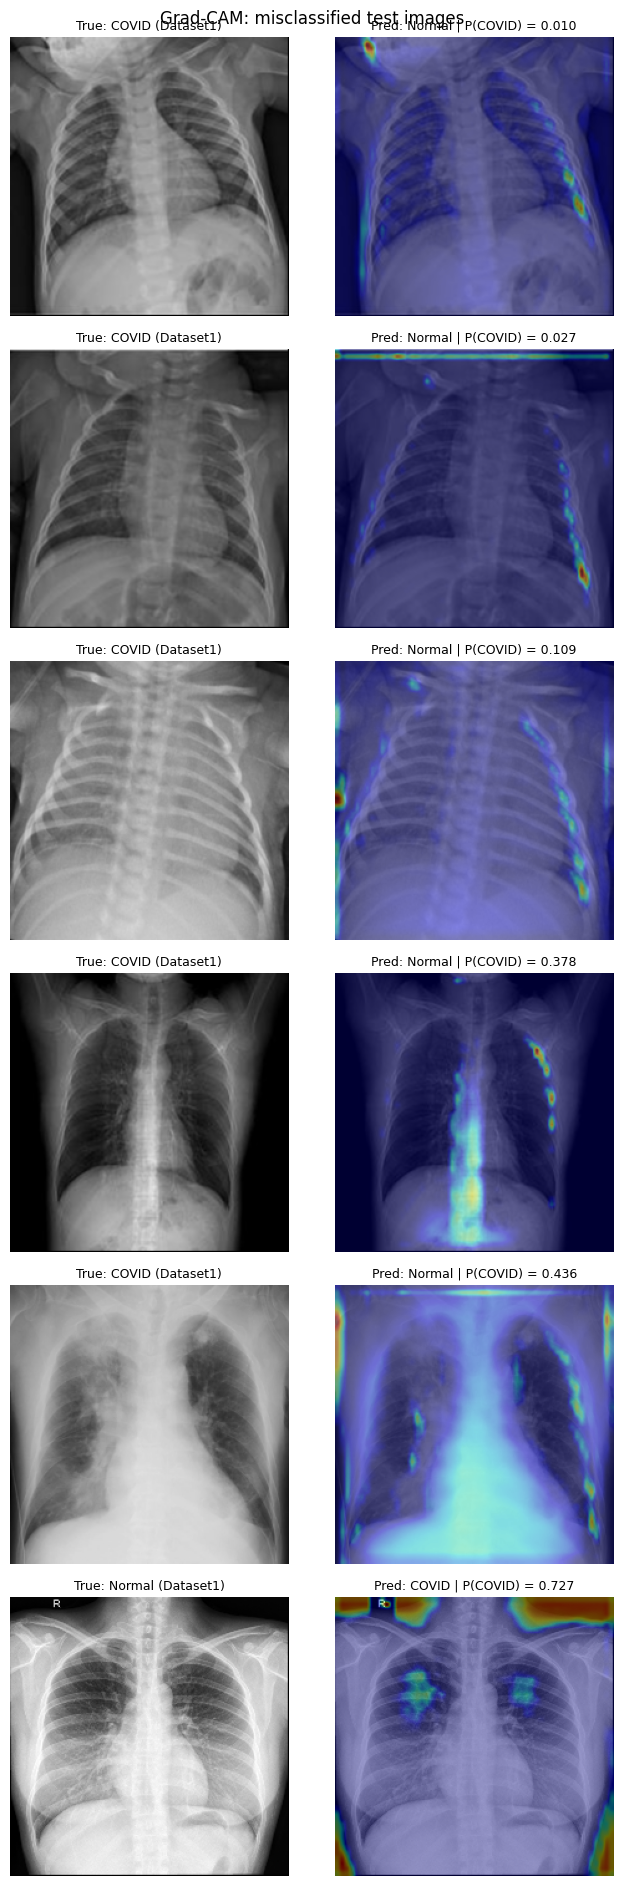

In [52]:
wrong = res[~res["correct"]].sort_values("prob_covid")
show_gradcam(wrong, "Grad-CAM: misclassified test images")

**Grad-CAM on misclassified images.**

For the 5 missed COVID cases, the heatmaps show the evidence the model used to predict *Normal*. In none of them is the lung tissue the main focus. Instead, activation concentrates on (1) the **lateral chest wall and rib margins**, i.e. the outline and shape of the ribcage, and (2) **image borders**, including a strong band along the top edge in one case. In the P = 0.436 case, the visibly abnormal right lung is not highlighted at all.

The single false positive (Normal predicted as COVID, P = 0.727) does show activation in both perihilar lung regions, but also strong activation in the image corners, the top border, and around the "R" marker.

Together with the error analysis (the most confident misses are pediatric-looking COVID images), this suggests the model relies substantially on **ribcage shape (a proxy for patient age)** and **image-border artifacts** rather than COVID-specific lung findings.

Caveat: the explained layer is only the third convolutional layer of a shallow network, whose features are relatively low-level and naturally respond to strong edges such as rib margins and image borders. The heatmaps are therefore strong but not conclusive evidence of shortcut learning; the comparison with correctly classified images below tests this further.

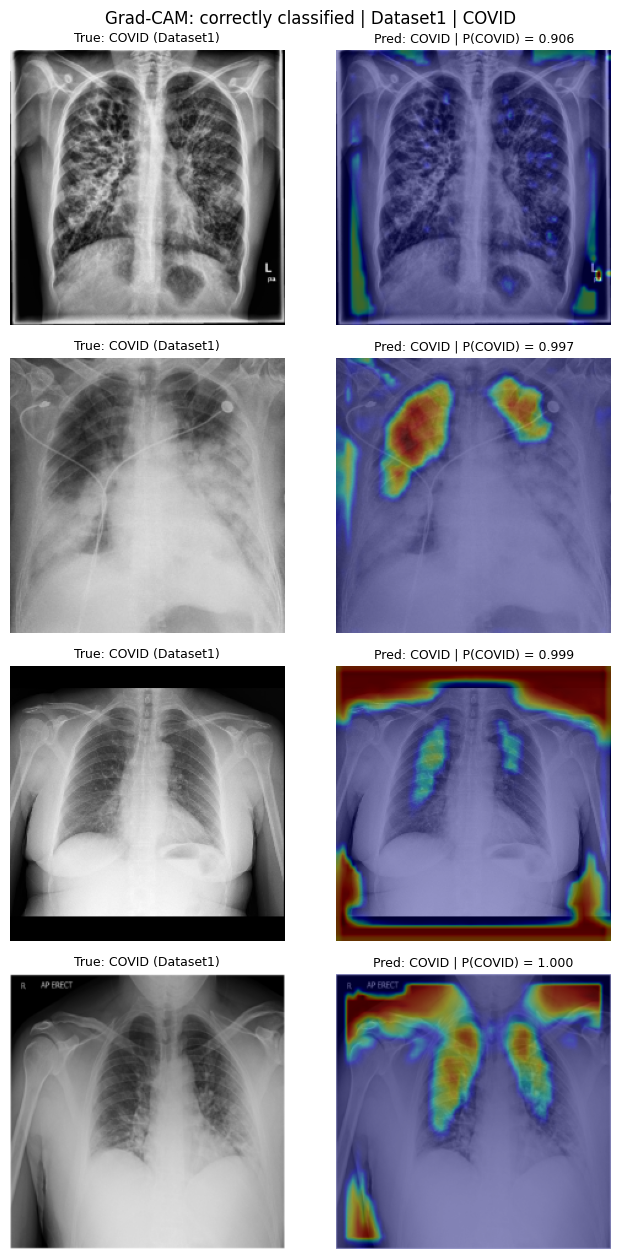

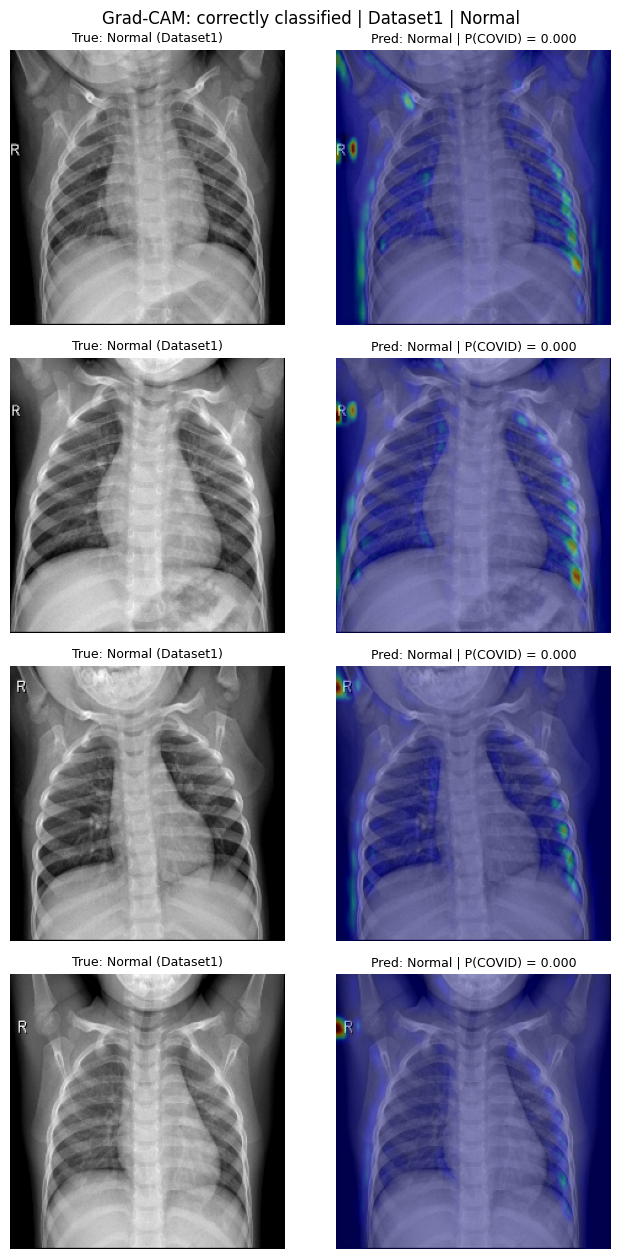

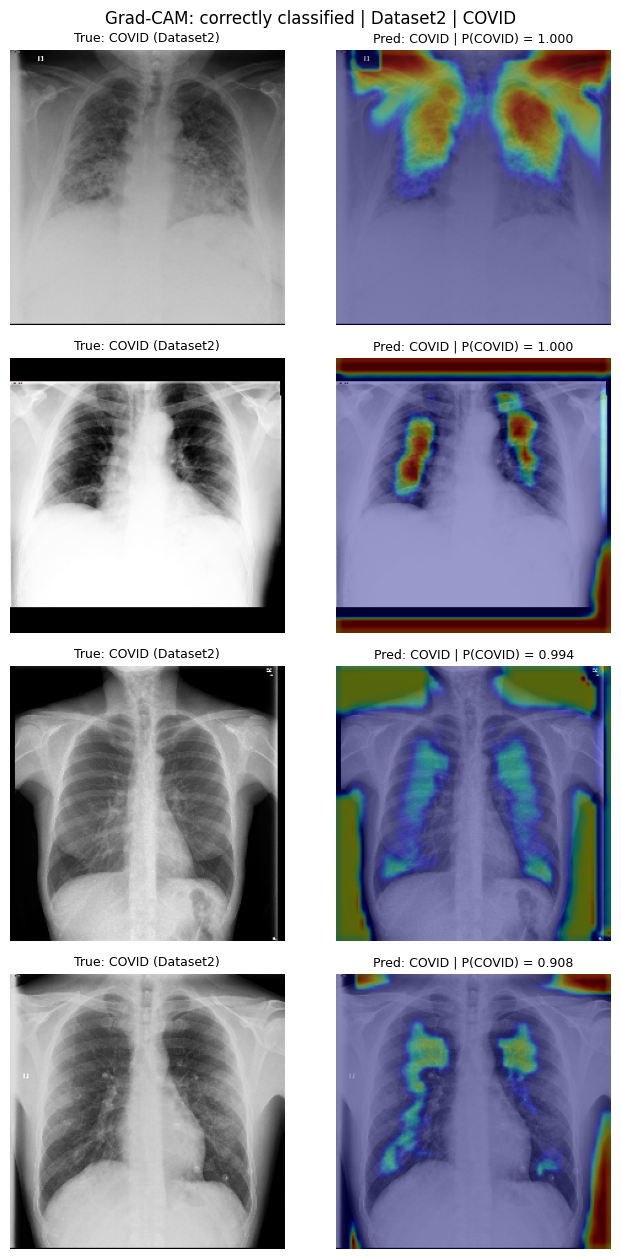

In [53]:
#grad cam on correctly classified groups
correct = res[res["correct"]]
for (src, cls), g in correct.groupby(["source", "class"]):
    show_gradcam(
        g.sample(min(4, len(g)), random_state=SEED),
        f"Grad-CAM: correctly classified | {src} | {cls}"
    )

In [54]:
def border_fraction(cam, band=0.10):
    h, w = cam.shape
    b = int(h * band)
    inner = cam[b:h - b, b:w - b].sum()
    return 1 - inner / (cam.sum() + 1e-8)

fractions = []
for _, r in tqdm(res.iterrows(), total=len(res), desc="Grad-CAM on test set"):
    img, _ = load_and_preprocess_image(r["filepath"], 0)
    cam, _ = gradcam(img.numpy())
    fractions.append(border_fraction(cam))

res["border_frac"] = fractions
print("Share of Grad-CAM heat in the outer 10% border (uniform = 0.36):\n")
print(res.groupby(["source", "class", "correct"])["border_frac"].agg(["mean", "count"]).round(3))

Grad-CAM on test set:   0%|          | 0/411 [00:00<?, ?it/s]

Share of Grad-CAM heat in the outer 10% border (uniform = 0.36):

                          mean  count
source   class  correct              
Dataset1 COVID  False    0.427      5
                True     0.424    136
         Normal False    0.848      1
                True     0.498    198
Dataset2 COVID  True     0.608     71


**Grad-CAM on correctly classified images.**

*Dataset1 Normal:* activation is faint and limited to the outer rib margins and the "R" marker, with no activation inside the lungs. The model's evidence for "Normal" is the pediatric ribcage outline and hospital-specific markers, consistent with the misclassified cases.

*Dataset1 COVID:* mixed. Some images show focused activation on the upper lung zones, but others show strong activation on image borders, text annotations ("AP ERECT"), laterality markers ("L"), and corners.

*Dataset2 COVID:* all examples show clear lung activation, but most also show activation outside the body: black padding bars, background beside the patient, and image borders.

**Border-activation measure.** The share of Grad-CAM heat in the outer 10% of the image (0.36 if evenly spread) was 0.42 for Dataset1 COVID, 0.50 for Dataset1 Normal, and **0.61 for Dataset2 COVID**, the only source whose non-square images receive padding and the only group with 100% test accuracy.

**Conclusion.** The model does use lung regions when predicting COVID, but its decisions are also driven by non-medical cues: pediatric ribcage shape for Normal, and borders, padding, markers, and text for COVID, most strongly for Dataset2. Moreover, because all COVID images are adult and all Normal images are pediatric, lung activation itself is ambiguous: the model may be detecting adult versus pediatric lung appearance rather than COVID-specific opacities. The near-perfect test scores therefore overstate the model's ability to detect COVID, and cannot be expected to generalise to adult Normal X-rays from other hospitals.